# Lab 01 · 공개 가중치를 열어 보기: 설정, 파라미터, 토큰, 그리고 한 토큰이 만들어지는 과정

**대응하는 공부 단계**: [02_study-method.md](../02_study-method.md)의 2단계(가중치 열어 보기)와 3단계(한 토큰이 만들어지는 과정)

| 절 | 직접 확인할 것 | 관련 문서 |
|---|---|---|
| 1 | `config.json`에 적힌 구조 선택들 | [03_training-pipeline.md](../03_training-pipeline.md) 3절 |
| 2 | 파라미터 이름·shape, **손으로 센 파라미터 수 = 모델 카드의 숫자** | [02_study-method.md](../02_study-method.md) 2단계 |
| 3 | 토크나이저가 한국어와 영어를 쪼개는 방식 | [LLM Lab 01](../../04_NLP_LLM/labs/lab01_tokenizer_attention_from_scratch.ipynb) |
| 4 | logits → 확률 → 샘플링, `generate()` 없이 직접 생성 | [03_training-pipeline.md](../03_training-pipeline.md) 9절 |
| 5 | 층을 지나며 답이 정해지는 모습 (logit lens) | 해석가능성 입문 |
| 6 | base 모델과 instruct 모델의 차이, 채팅 템플릿 | [03_training-pipeline.md](../03_training-pipeline.md) 6절 |

**대상 모델**: `HuggingFaceTB/SmolLM2-135M` (Apache-2.0). 약 1억 3천만 파라미터라 노트북 CPU에서 몇 초면 돕니다. 구조는 수백억 파라미터 모델과 같은 계열(Llama 방식의 디코더)이라, 여기서 본 것이 큰 모델에도 그대로 적용됩니다.

**소요 시간**: 90분 · **패키지**: torch, transformers, matplotlib · 모델 약 0.5GB 다운로드

In [1]:
import math, json, warnings, numpy as np, matplotlib.pyplot as plt, torch, torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForCausalLM
warnings.filterwarnings("ignore"); torch.manual_seed(0)
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

name = "HuggingFaceTB/SmolLM2-135M"
tok = AutoTokenizer.from_pretrained(name)
model = AutoModelForCausalLM.from_pretrained(name, attn_implementation="eager").float().eval()   # eager: 어텐션 가중치를 꺼내 보기 위해
print(type(model).__name__)

LlamaForCausalLM


## 1. 설정 파일 읽기

`config.json`은 구조에 대한 모든 결정을 담고 있습니다. [학습 과정 문서 3절](../03_training-pipeline.md)의 "요즘 흔한 선택" 표와 대조해 보세요.

✍️ **예측**: 이 모델은 몇 층일까요? 폭(hidden size)은? 폭이 좁고 층이 많은 쪽일까요, 넓고 얕은 쪽일까요?

In [2]:
cfg = model.config
keys = ["vocab_size", "hidden_size", "num_hidden_layers", "num_attention_heads", "num_key_value_heads", "intermediate_size",
        "max_position_embeddings", "hidden_act", "rms_norm_eps", "rope_theta", "tie_word_embeddings"]
for k in keys: print(f"{k:26s} = {getattr(cfg, k, '(없음)')}")

vocab_size                 = 49152
hidden_size                = 576
num_hidden_layers          = 30
num_attention_heads        = 9
num_key_value_heads        = 3
intermediate_size          = 1536
max_position_embeddings    = 8192
hidden_act                 = silu
rms_norm_eps               = 1e-05
rope_theta                 = (없음)
tie_word_embeddings        = True


읽는 법
- `num_attention_heads` 와 `num_key_value_heads` 가 다르면 **GQA**입니다. 여러 Query 헤드가 Key·Value 헤드를 나눠 씁니다.
- 위치 정보는 **RoPE**로 줍니다. 2절의 파라미터 목록에 위치 임베딩 테이블이 없다는 것으로 확인할 수 있습니다(라이브러리 버전에 따라 `rope_theta` 항목이 config에 보이지 않을 수 있습니다).
- `rms_norm_eps` → 정규화는 **RMSNorm**, `hidden_act = silu` + 게이트 구조 → **SwiGLU** 계열 FFN.
- `tie_word_embeddings = True` → 입력 임베딩과 출력층이 **같은 행렬**을 씁니다.

## 2. 파라미터를 직접 세기

가중치 파일은 "이름 → 숫자 배열"의 사전입니다. 첫 블록의 내용물을 봅니다.

✍️ **예측**: 전체 파라미터 중 임베딩(어휘 × 폭)이 차지하는 비율은 몇 %일까요?

In [3]:
for n, p in model.named_parameters():
    if n.startswith("model.embed_tokens") or ".layers.0." in n or n.startswith("model.norm") or n.startswith("lm_head"):
        print(f"{n:55s} {tuple(p.shape)}")
total = sum(p.numel() for p in model.parameters())
print(f"\n실제 파라미터 수 = {total:,}")

model.embed_tokens.weight                               (49152, 576)
model.layers.0.self_attn.q_proj.weight                  (576, 576)
model.layers.0.self_attn.k_proj.weight                  (192, 576)
model.layers.0.self_attn.v_proj.weight                  (192, 576)
model.layers.0.self_attn.o_proj.weight                  (576, 576)
model.layers.0.mlp.gate_proj.weight                     (1536, 576)
model.layers.0.mlp.up_proj.weight                       (1536, 576)
model.layers.0.mlp.down_proj.weight                     (576, 1536)
model.layers.0.input_layernorm.weight                   (576,)
model.layers.0.post_attention_layernorm.weight          (576,)
model.norm.weight                                       (576,)

실제 파라미터 수 = 134,515,008


In [4]:
V, d, L, I = cfg.vocab_size, cfg.hidden_size, cfg.num_hidden_layers, cfg.intermediate_size
h, kv = cfg.num_attention_heads, cfg.num_key_value_heads
d_head = d // h
embedding = V * d
attention = d * d + 2 * (kv * d_head) * d + d * d          # q, k, v, o  (k와 v는 헤드 수가 적어 더 작다)
mlp = 3 * d * I                                             # gate, up, down
norms = 2 * d                                               # 블록마다 RMSNorm 두 개
by_hand = embedding + L * (attention + mlp + norms) + d    # + 마지막 RMSNorm. 출력층은 임베딩과 공유라 더하지 않는다
print(f"손으로 계산한 파라미터 수 = {by_hand:,}   (실제와 일치: {by_hand == total})")
parts = {"embedding (shared with output)": embedding, "attention": L * attention, "MLP (feed-forward)": L * mlp, "norms": L * norms + d}
for k, v in parts.items(): print(f"  {k:32s} {v:>12,}  {v / total:6.1%}")

손으로 계산한 파라미터 수 = 134,515,008   (실제와 일치: True)
  embedding (shared with output)     28,311,552   21.0%
  attention                          26,542,080   19.7%
  MLP (feed-forward)                 79,626,240   59.2%
  norms                                  35,136    0.0%


- config의 숫자 몇 개만으로 파라미터 수가 **정확히** 재현됩니다. 모델 카드의 "135M"이 어디서 나온 숫자인지 이제 압니다.
- 작은 모델에서는 임베딩이 큰 비율을 차지합니다. 어휘 크기는 모델 크기와 무관하게 수만 개이기 때문입니다. 폭이 커지면 블록 쪽(폭의 제곱에 비례)이 압도하게 됩니다.
- FFN(MLP)이 어텐션보다 파라미터가 많습니다. "Transformer = 어텐션"이라는 인상과 달리 파라미터의 다수는 FFN에 있습니다.

## 3. 토크나이저

✍️ **예측**: 같은 뜻의 한국어 문장과 영어 문장 중 어느 쪽이 토큰이 더 많이 나올까요?

In [5]:
for s in ["Data scientists read the data before the model.", "데이터 사이언티스트는 모델보다 데이터를 먼저 본다.", " Paris", "Paris", "unbelievably"]:
    ids = tok.encode(s, add_special_tokens=False)
    print(f"{len(s):3d} chars → {len(ids):3d} tokens | {s!r} → {[tok.decode([i]) for i in ids][:12]}{' ...' if len(ids) > 12 else ''}")
print("\n특수 토큰:", tok.special_tokens_map)

 47 chars →   9 tokens | 'Data scientists read the data before the model.' → ['Data', ' scientists', ' read', ' the', ' data', ' before', ' the', ' model', '.']
 28 chars →  58 tokens | '데이터 사이언티스트는 모델보다 데이터를 먼저 본다.' → ['�', '�', '�', '이', '�', '�', '�', ' �', '��', '이', '�', '�'] ...
  6 chars →   1 tokens | ' Paris' → [' Paris']
  5 chars →   1 tokens | 'Paris' → ['Paris']
 12 chars →   4 tokens | 'unbelievably' → ['un', 'belie', 'v', 'ably']

특수 토큰: {'bos_token': '<|endoftext|>', 'eos_token': '<|endoftext|>', 'unk_token': '<|endoftext|>'}


- 이 모델의 토크나이저는 영어 위주의 데이터로 만들어져 한국어는 거의 바이트 단위로 쪼개집니다. **이 모델이 한국어를 못하는 이유의 절반은 여기서 이미 정해져 있습니다.**
- `" Paris"` 와 `"Paris"` 는 다른 토큰입니다. 단어 앞의 공백이 토큰에 포함됩니다.

## 4. 한 토큰이 만들어지는 과정

모델의 출력은 "다음 토큰이 어휘의 각 항목일 점수(logits)"입니다. softmax를 거치면 확률이 됩니다.

✍️ **예측**: `"The capital of France is"` 다음 토큰의 1위는? 그 확률은 몇 %쯤일까요?

In [6]:
prompt = "The capital of France is"
inputs = tok(prompt, return_tensors="pt")
with torch.no_grad(): out = model(**inputs, output_hidden_states=True, output_attentions=True)
print("입력 토큰 수:", inputs["input_ids"].shape[1], "| logits shape:", tuple(out.logits.shape), "= (배치, 위치, 어휘)")
last = out.logits[0, -1]                                    # 마지막 위치의 logits = 다음 토큰에 대한 예측
probs = F.softmax(last, dim=-1)
top = torch.topk(probs, 8)
for p, i in zip(top.values, top.indices): print(f"  {tok.decode([i.item()])!r:12s} {p.item():.3f}")

입력 토큰 수: 5 | logits shape: (1, 5, 49152) = (배치, 위치, 어휘)
  ' the'       0.262
  ' Paris'     0.094
  ' located'   0.073
  ' called'    0.044
  ' a'         0.039
  ' situated'  0.036
  ' in'        0.016
  ' '          0.012


1위가 `Paris`가 아니라 ` the`일 수 있습니다. 작은 base 모델은 "사실을 답하는" 것이 아니라 "그럴듯하게 이어 쓰는" 것이고, `is` 뒤에는 `the`가 흔하기 때문입니다.

**temperature**는 logits를 나누는 값입니다. 낮추면 분포가 뾰족해지고(결정적), 높이면 평평해집니다(다양).

In [7]:
def entropy(p): return -(p * torch.log(p + 1e-12)).sum().item()
for T in [0.5, 1.0, 1.5]:
    p = F.softmax(last / T, dim=-1)
    print(f"temperature {T}: 1위 확률 = {p.max().item():.3f},  분포의 엔트로피 = {entropy(p):.2f} nats")

temperature 0.5: 1위 확률 = 0.772,  분포의 엔트로피 = 0.93 nats
temperature 1.0: 1위 확률 = 0.262,  분포의 엔트로피 = 4.41 nats
temperature 1.5: 1위 확률 = 0.050,  분포의 엔트로피 = 7.80 nats


이제 `generate()`를 쓰지 않고 직접 생성합니다. **가장 확률 높은 토큰을 붙이고, 다시 넣는 것**을 반복할 뿐입니다.

In [8]:
@torch.no_grad()
def my_generate(prompt, max_new_tokens=12, temperature=0.0, seed=0):
    g = torch.Generator().manual_seed(seed)
    ids = tok(prompt, return_tensors="pt")["input_ids"]
    for _ in range(max_new_tokens):
        logits = model(ids).logits[0, -1]
        if temperature == 0: nxt = logits.argmax().view(1, 1)                                    # greedy
        else: nxt = torch.multinomial(F.softmax(logits / temperature, dim=-1), 1, generator=g).view(1, 1)
        ids = torch.cat([ids, nxt], dim=1)
    return tok.decode(ids[0])

mine = my_generate(prompt)
ref = tok.decode(model.generate(**inputs, max_new_tokens=12, do_sample=False)[0])
print("직접 구현 (greedy):", repr(mine)); print("model.generate  :", repr(ref)); print("같은가:", mine == ref)
for seed in range(3): print(f"temperature 1.0, seed {seed}:", repr(my_generate(prompt, temperature=1.0, seed=seed)))

직접 구현 (greedy): 'The capital of France is the capital of the country.\n\nThe capital of France'
model.generate  : 'The capital of France is the capital of the country.\n\nThe capital of France'
같은가: True


temperature 1.0, seed 0: 'The capital of France is the towns of Bordeaux, Cavaippa,'


temperature 1.0, seed 1: 'The capital of France is the fourteenth largest capital in the world and located in southeastern France'


temperature 1.0, seed 2: 'The capital of France is probably the most ruins-eared place in the world, if'


- 직접 만든 루프가 `generate()`와 같은 글을 냅니다. 생성은 마법이 아니라 **forward를 반복 호출**하는 것입니다. (실제 구현은 이미 계산한 키·값을 재사용하는 KV 캐시로 훨씬 빠르게 합니다.)
- temperature가 0보다 크면 같은 프롬프트에서도 매번 다른 글이 나옵니다. 평가할 때 샘플링 설정을 기록해야 하는 이유입니다.

## 5. Logit lens: 답은 몇 번째 층에서 정해지는가

마지막 층의 출력만 출력층에 넣는 대신, **중간 층의 출력**을 꺼내 같은 출력층에 넣어 봅니다. "이 층까지만 계산했다면 무엇을 예측했을까"를 보는 간단한 해석 기법입니다.

✍️ **예측**: 최종 1위 토큰의 확률은 층이 깊어짐에 따라 서서히 오를까요, 어느 층에서 갑자기 오를까요?

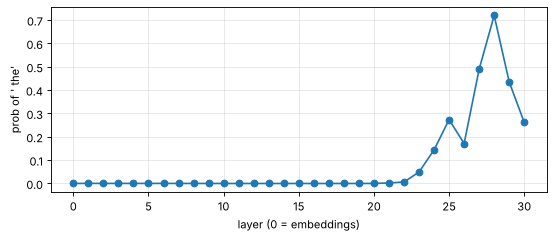

층별 1위 예측: [' is', ' a', '.', '.', ' (', ' ', ' ', ' ', ' ', '.', '.', ' ', ',', ',', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' the', ' the', ' the', ' the']


In [9]:
answer_id = top.indices[0].item()
layer_probs, layer_top = [], []
n_states = len(out.hidden_states)
for k, hs in enumerate(out.hidden_states):                  # 임베딩 출력 + 각 층의 출력 = (층 수 + 1)개
    logits = out.logits[0, -1] if k == n_states - 1 else model.lm_head(model.model.norm(hs[0, -1]))   # 중간 층: 마지막 정규화 → 출력층
    p = F.softmax(logits, dim=-1)
    layer_probs.append(p[answer_id].item()); layer_top.append(tok.decode([p.argmax().item()]))
plt.figure(figsize=(8, 3)); plt.plot(layer_probs, "o-"); plt.xlabel("layer (0 = embeddings)"); plt.ylabel(f"prob of {tok.decode([answer_id])!r}"); plt.show()
print("층별 1위 예측:", layer_top)

앞쪽 층에서는 엉뚱한 토큰이 1위이고, 마지막 몇 층에서야 최종 1위 토큰의 확률이 올라옵니다. 층마다 표현이 조금씩 다듬어지고(잔차 연결로 **더해 가며**), 마지막 몇 층에서 출력에 맞는 형태가 됩니다. 이 그림은 프롬프트마다 다릅니다. 여러 프롬프트로 직접 해 보세요.

어텐션 가중치도 꺼내 볼 수 있습니다. 마지막 위치(다음 토큰을 예측하는 자리)가 앞의 어느 토큰을 참고했는지 봅니다.

어텐션 텐서 shape (층, 헤드, 질의 위치, 키 위치): (30, 9, 5, 5)


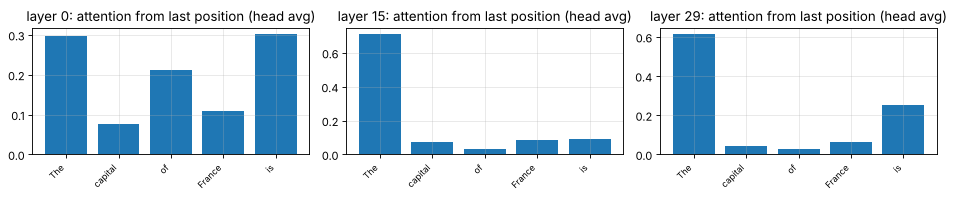

In [10]:
tokens = [tok.decode([i]) for i in inputs["input_ids"][0]]
att = torch.stack(out.attentions)[:, 0]                      # (층, 헤드, 위치, 위치)
print("어텐션 텐서 shape (층, 헤드, 질의 위치, 키 위치):", tuple(att.shape))
fig, axes = plt.subplots(1, 3, figsize=(12, 2.6))
for ax, layer in zip(axes, [0, cfg.num_hidden_layers // 2, cfg.num_hidden_layers - 1]):
    ax.bar(range(len(tokens)), att[layer, :, -1, :].mean(0).numpy()); ax.set_xticks(range(len(tokens))); ax.set_xticklabels(tokens, rotation=45, ha="right", fontsize=8)
    ax.set_title(f"layer {layer}: attention from last position (head avg)")
plt.tight_layout(); plt.show()

## 6. base 모델과 instruct 모델

지금까지 쓴 것은 사전학습만 한 **base 모델**입니다. 질문을 넣으면 답하는 것이 아니라 **이어서 씁니다.** 같은 계열의 instruct 모델(SFT 등 후처리 학습을 거친 것)과 비교합니다.

✍️ **예측**: base 모델에 "What is the capital of France?"를 넣으면 무엇이 나올까요?

In [11]:
question = "What is the capital of France?"
print("base 모델     :", repr(tok.decode(model.generate(**tok(question, return_tensors="pt"), max_new_tokens=25, do_sample=False)[0])))

inst_name = "HuggingFaceTB/SmolLM2-135M-Instruct"
itok = AutoTokenizer.from_pretrained(inst_name); imodel = AutoModelForCausalLM.from_pretrained(inst_name).float().eval()
chat = itok.apply_chat_template([{"role": "user", "content": question}], add_generation_prompt=True, tokenize=False)
print("\n채팅 템플릿을 적용한 실제 입력 문자열:\n" + chat)
ids = itok(chat, return_tensors="pt", add_special_tokens=False)
gen = imodel.generate(**ids, max_new_tokens=25, do_sample=False)
print("instruct 모델 :", repr(itok.decode(gen[0][ids["input_ids"].shape[1]:], skip_special_tokens=True)))

base 모델     : 'What is the capital of France?\n\nThe capital of France is Paris.\n\nWhat is the capital of France?\n\nThe capital of France is'



채팅 템플릿을 적용한 실제 입력 문자열:
<|im_start|>system
You are a helpful AI assistant named SmolLM, trained by Hugging Face<|im_end|>
<|im_start|>user
What is the capital of France?<|im_end|>
<|im_start|>assistant



instruct 모델 : 'The capital of France is Paris.'


- base 모델은 질문을 "문서의 일부"로 보고 이어 씁니다. instruct 모델은 `<|im_start|>user … <|im_end|>` 같은 **역할 구분 토큰**으로 감싼 입력을 보고 "이제 내가 답할 차례"라는 것을 학습했습니다.
- 채팅 템플릿은 모델마다 다르고 토크나이저 설정 파일에 들어 있습니다. 템플릿을 빼먹거나 다른 모델의 것을 쓰면 성능이 크게 떨어집니다. 평가 숫자를 재현할 때 자주 틀리는 지점입니다.
- 두 모델의 **구조와 파라미터 수는 같습니다.** 달라진 것은 가중치의 값뿐이고, 그 차이를 만든 것이 후처리 학습입니다.

---
## 직접 해보기

1. **(top-p 샘플링)** 확률이 높은 토큰부터 누적 확률이 p(예: 0.9)를 넘을 때까지만 남기고 그 안에서 샘플링하는 top-p를 `my_generate`에 추가하세요.
2. **(크기와 비율)** 폭 `d`가 2배(1152)가 되고 나머지 비율이 같다면 임베딩의 비중은 얼마가 될까요? 2절의 식으로 계산하세요.
3. **(다른 프롬프트의 logit lens)** `"Two plus two equals"` 로 5절을 다시 실행해 보세요. 정답이 올라오는 층이 같은가요?
4. **(모델 해부 노트)** 이 노트북에서 확인한 값으로 [모델 해부 노트 템플릿](../../_templates/model_study.md)의 1~3절을 채우세요.

In [12]:
# TODO 1: top-p 샘플링

# TODO 2: 폭이 2배일 때 임베딩 비중

# TODO 3: 다른 프롬프트로 logit lens

---
## 정답 예시 (먼저 풀어 본 뒤 확인)

In [13]:
# 1. top-p (nucleus) 샘플링
def top_p_filter(probs, p=0.9):
    sorted_p, idx = torch.sort(probs, descending=True)
    keep = torch.cumsum(sorted_p, 0) - sorted_p < p         # 이 토큰을 넣기 전의 누적 확률이 p 미만이면 유지
    filtered = torch.zeros_like(probs); filtered[idx[keep]] = sorted_p[keep]
    return filtered / filtered.sum()

p_full = F.softmax(last, dim=-1); p_nucleus = top_p_filter(p_full, 0.9)
print(f"어휘 {len(p_full):,}개 중 확률 0이 아닌 토큰: 원래 분포 {int((p_full > 1e-6).sum()):,}개 → top-p 0.9 적용 후 {int((p_nucleus > 0).sum())}개")

어휘 49,152개 중 확률 0이 아닌 토큰: 원래 분포 7,929개 → top-p 0.9 적용 후 406개


In [14]:
# 2. 폭이 2배라면 (층 수·헤드 구성·FFN 배율은 그대로)
d2, I2 = 2 * d, 2 * I
emb2 = V * d2; block2 = (d2 * d2 + 2 * (kv * (d2 // h)) * d2 + d2 * d2) + 3 * d2 * I2 + 2 * d2
total2 = emb2 + L * block2 + d2
print(f"폭 {d} → 임베딩 비중 {embedding / total:.1%}   |   폭 {d2} → 총 {total2 / 1e6:.0f}M, 임베딩 비중 {emb2 / total2:.1%}")

폭 576 → 임베딩 비중 21.0%   |   폭 1152 → 총 481M, 임베딩 비중 11.8%


In [15]:
# 3. 다른 프롬프트
ins2 = tok("Two plus two equals", return_tensors="pt")
with torch.no_grad(): out2 = model(**ins2, output_hidden_states=True)
final_id = out2.logits[0, -1].argmax().item()
probs2 = [F.softmax(model.lm_head(model.model.norm(hs[0, -1])), dim=-1)[final_id].item() for hs in out2.hidden_states[:-1]] + [F.softmax(out2.logits[0, -1], dim=-1)[final_id].item()]
print("최종 1위 토큰:", repr(tok.decode([final_id])), "| 층별 확률:", [round(p, 2) for p in probs2])

최종 1위 토큰: ' four' | 층별 확률: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.01, 0.06, 0.33, 0.33, 0.36, 0.22]


---
## 문서로 돌아가기

| 방금 한 것 | 확인할 곳 |
|---|---|
| 1절 config | [SmolLM2 모델 카드](https://huggingface.co/HuggingFaceTB/SmolLM2-135M)와 논문의 구조 설명. 같은 값을 찾을 수 있는가 |
| 2절 파라미터 세기 | 다른 공개 모델(예: `EleutherAI/pythia-70m`)에서 같은 계산을 해 보기. 구조가 달라(GPT-NeoX) 식이 조금 바뀐다 |
| 5절 logit lens | [*A Mathematical Framework for Transformer Circuits*](https://transformer-circuits.pub/2021/framework/index.html)의 "잔차 스트림" 관점 |
| 6절 base vs instruct | [03_training-pipeline.md](../03_training-pipeline.md) 6절 후처리 학습 |

## 기억 점검

1. config의 어떤 값들로 파라미터 수를 계산할 수 있나? 작은 모델에서 임베딩 비중이 큰 이유는?
2. GQA는 config에서 어떻게 알아볼 수 있고, 무엇을 줄이기 위한 것인가?
3. logits, 확률, temperature의 관계를 설명하라.
4. `generate()`가 내부에서 하는 일을 세 줄로 설명하라.
5. base 모델과 instruct 모델은 무엇이 같고 무엇이 다른가? 채팅 템플릿은 왜 필요한가?

<details><summary>답 확인</summary>

1. 어휘 크기, 폭, 층 수, FFN 크기, 헤드 수(와 KV 헤드 수), 가중치 공유 여부. 어휘 크기는 모델 크기와 무관하게 크고, 블록의 파라미터는 폭의 제곱에 비례해 작은 모델에서는 작기 때문.
2. `num_key_value_heads` 가 `num_attention_heads` 보다 작다. K·V 투영 행렬과 추론 때의 KV 캐시 메모리를 줄인다.
3. logits는 정규화 전 점수, softmax를 거치면 확률. temperature로 logits를 나눈 뒤 softmax를 하며, 낮을수록 1위에 확률이 몰린다(0이면 greedy).
4. 현재 토큰열을 넣어 마지막 위치의 logits를 얻는다 → 샘플링 규칙으로 다음 토큰을 고른다 → 붙여서 반복(종료 토큰이나 길이 제한까지).
5. 구조와 파라미터 수는 같고 가중치 값이 다르다(후처리 학습). 채팅 템플릿은 대화의 역할과 경계를 학습 때와 같은 토큰열로 표현해, 모델이 "답할 차례"를 알게 한다.
</details>